# Задание 4.5

Предположим, что «несимметричную» («неправильную») монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд (вероятность выпадения «герба» равна $p=0{,}7$). Постройте вероятностную модель, т.е. $(\Omega,\mathbb P(\cdot))$, и найдите вероятность того, что потребуется:

- **а)** чётное число бросаний;
- **б)** число бросаний кратно 4.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

Обозначим $p=\mathbb P(\text{Г})=0{,}7$, $q=1-p=0{,}3$, $\tau$ — число бросаний.

**Пространство исходов** то же, что в задаче 4.4: $\Omega=\{\omega_n^{\text{Г}},\omega_n^{\text{Р}}:n\ge2\}$, где $\omega_n^{\text{Г}}$ — чередование длины $n-1$, начинающееся с Г, плюс повтор последней стороны. Но теперь исходы одной длины **не равновероятны**.

**Вероятности исходов.**

*Чётное $n=2k$.* Чередование длины $2k-1$, начинающееся с Г, содержит $k$ гербов и $k-1$ решку и кончается гербом, затем ещё один Г:

$$
\mathbb P(\omega_{2k}^{\text{Г}})=p^{k+1}q^{k-1},\qquad \mathbb P(\omega_{2k}^{\text{Р}})=q^{k+1}p^{k-1}
\ \Rightarrow\ \mathbb P(\tau=2k)=(pq)^{k-1}(p^2+q^2).
$$

*Нечётное $n=2k+1$.* Чередование длины $2k$ содержит $k$ гербов и $k$ решек; если начали с Г, то кончили Р и повторяем Р:

$$
\mathbb P(\omega_{2k+1}^{\text{Г}})=p^{k}q^{k+1},\qquad \mathbb P(\omega_{2k+1}^{\text{Р}})=q^{k}p^{k+1}
\ \Rightarrow\ \mathbb P(\tau=2k+1)=(pq)^k(p+q)=(pq)^k .
$$

**Нормировка:** $\displaystyle\sum_{k\ge1}(pq)^{k-1}(p^2+q^2)+\sum_{k\ge1}(pq)^k=\frac{p^2+q^2+pq}{1-pq}=\frac{1-pq}{1-pq}=1$ (так как $p^2+q^2=1-2pq$).

**а) Чётное число бросаний:**

$$
\mathbb P(\tau\ \text{чётно})=\sum_{k\ge1}(pq)^{k-1}(p^2+q^2)=\frac{p^2+q^2}{1-pq}=\frac{0{,}58}{0{,}79}=\frac{58}{79}\approx0{,}734177 .
$$

**б) Число бросаний кратно 4** ($\tau=4m$, т.е. $k=2m$):

$$
\mathbb P(4\mid\tau)=\sum_{m\ge1}(pq)^{2m-1}(p^2+q^2)=\frac{(p^2+q^2)\,pq}{1-(pq)^2}=\frac{0{,}58\cdot0{,}21}{1-0{,}0441}=\frac{1218}{9559}\approx0{,}127419 .
$$

*Проверка:* при $p=q=\frac12$ формула а) даёт $\frac{1/2}{3/4}=\frac23$ — ответ задачи 4.4.

Нормировка Σ P(τ = n) = 1
а) P(τ чётно)    = 58/79 = 0.734177
б) P(τ кратно 4) = 1218/9559 = 0.127419


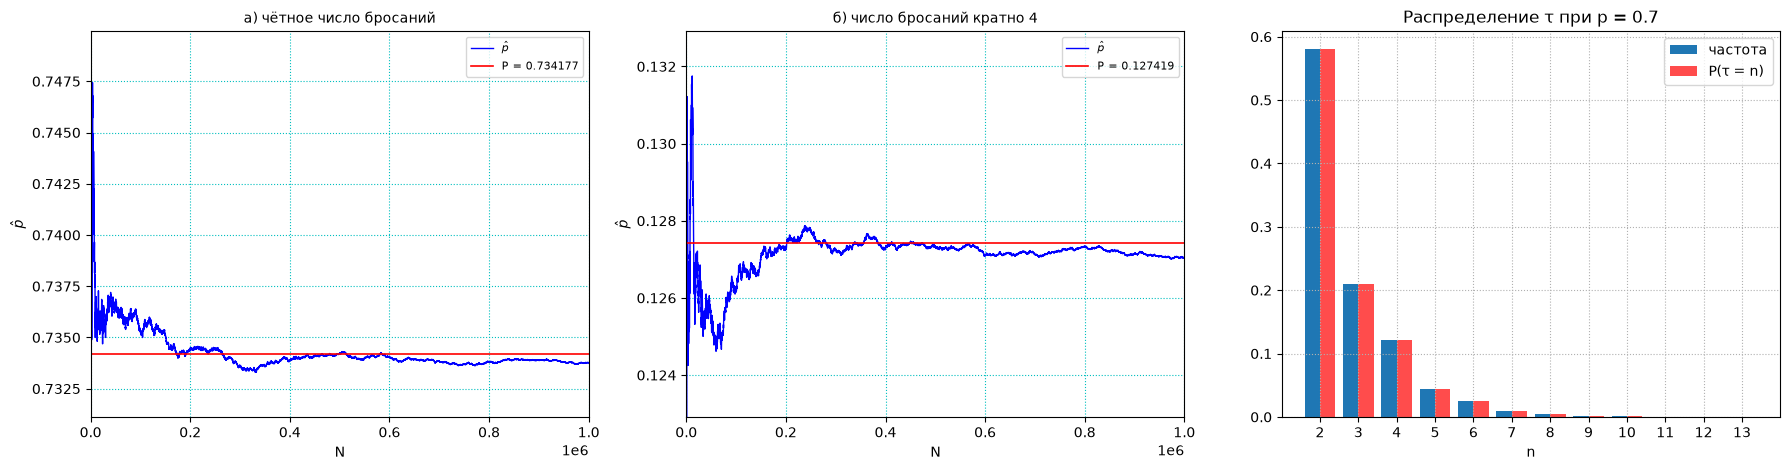

Моделирование (N = 1000000): p̂(чётно) = 0.733768,  p̂(кратно 4) = 0.127034


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точные вероятности (символьно, через суммы рядов) ----------
p = sp.Rational(7, 10)
k, m = sp.symbols("k m", integer=True, positive=True)
q = 1 - p
P_even_k = (p*q)**(k - 1) * (p**2 + q**2)                    # P(τ = 2k)
P_odd_k = (p*q)**k                                           # P(τ = 2k+1)
norm = sp.summation(P_even_k, (k, 1, sp.oo)) + sp.summation(P_odd_k, (k, 1, sp.oo))
P_even = sp.summation(P_even_k, (k, 1, sp.oo))
P_four = sp.summation(P_even_k.subs(k, 2*m), (m, 1, sp.oo))
print(f"Нормировка Σ P(τ = n) = {sp.nsimplify(norm)}")
print(f"а) P(τ чётно)    = {sp.nsimplify(P_even)} = {float(P_even):.6f}")
print(f"б) P(τ кратно 4) = {sp.nsimplify(P_four)} = {float(P_four):.6f}")

# ---------- Моделирование ----------
N, K = 1_000_000, 80
t = rng.random((N, K)) < 0.7                                 # True — герб (p = 0.7)
same = t[:, 1:] == t[:, :-1]
tau = same.argmax(axis=1) + 2                                # число бросаний до двух одинаковых подряд

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
pa = plot_freq(axes[0], tau % 2 == 0, float(P_even), "а) чётное число бросаний")
pb = plot_freq(axes[1], tau % 4 == 0, float(P_four), "б) число бросаний кратно 4")
n = np.arange(2, 14)
theory = [float((p*q)**(j//2 - 1)*(p**2 + q**2)) if j % 2 == 0 else float((p*q)**(j//2)) for j in n]
axes[2].bar(n - 0.2, [(tau == j).mean() for j in n], width=0.4, label="частота")
axes[2].bar(n + 0.2, theory, width=0.4, color="red", alpha=0.7, label="P(τ = n)")
axes[2].set_xticks(n); axes[2].set_xlabel("n"); axes[2].set_title("Распределение τ при p = 0.7")
axes[2].grid(ls=":"); axes[2].legend()
fig.tight_layout()
plt.show()

print(f"Моделирование (N = {N}): p̂(чётно) = {pa:.6f},  p̂(кратно 4) = {pb:.6f}")